In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## grouped-box-plot

**Figure 1: Response length of the base model and our RL-trained model on GSM8K, MATH and AIME.** Boxes span the quartiles with the median as a line; whiskers reach 1.5× the interquartile range; each box summarizes 60 responses. RL training lengthens responses on every dataset and most on the hardest, AIME, where the median grows from 873 to 1,670 tokens (+797, versus +124 on GSM8K).

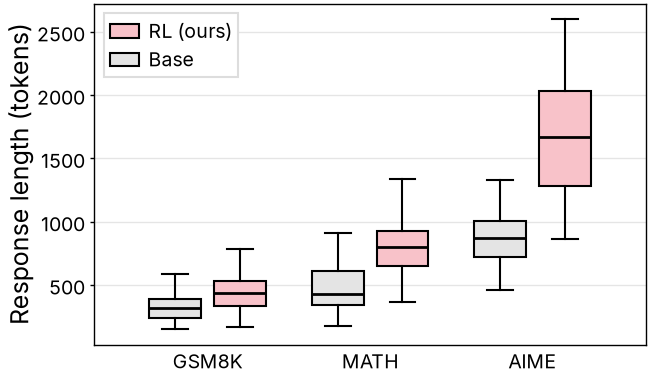

In [2]:
from matplotlib.patches import Patch

with open("../grouped-box-plot.json") as f:
    data = json.load(f)
datasets = data["datasets"]
models = {"Base": colors["neutral"], "RL (ours)": colors["ours"]}

fig, ax = plt.subplots(figsize=(3.25, 2))
x = np.arange(len(datasets))
width = 0.8 / len(models)
for i, (model, color) in enumerate(models.items()):
    for j, dataset in enumerate(datasets):
        box = ax.boxplot(data["lengths"][model][dataset], positions=[x[j] + (i - (len(models) - 1) / 2) * width],
                         widths=0.8 * width, showfliers=False)
        box["boxes"][0].set_facecolor(lighten(color))

ax.set_xticks(x, labels=datasets)
ax.tick_params(axis="x", length=0)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Response length (tokens)")
handles = [Patch(facecolor=lighten(colors["ours"]), edgecolor="black", linewidth=0.75, label="RL (ours)"),
           Patch(facecolor=lighten(colors["neutral"]), edgecolor="black", linewidth=0.75, label="Base")]
ax.legend(handles=handles, loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("grouped-box-plot.pdf")
fig.savefig("grouped-box-plot.png")
plt.show()